In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
file_path = r"C:\Users\Lenove\Documents\Project_01_ML01\lungcancerdata.xlsx"
df = pd.read_excel(file_path, nrows=10000)
df

,id,age,gender,country,diagnosis_date,cancer_stage,family_history,smoking_status,bmi,cholesterol_level,hypertension,asthma,cirrhosis,other_cancer,treatment_type,end_treatment_date,survived
0,1,64,Male,Sweden,2016-04-05,Stage I,Yes,Passive Smoker,29.4,199,0,0,1,0,Chemotherapy,end_treatment_date,0
1,2,50,Female,Netherlands,2023-04-20,Stage III,Yes,Passive Smoker,41.2,280,1,1,0,0,Surgery,end_treatment_date,1
2,3,65,Female,Hungary,2023-04-05,Stage III,Yes,Former Smoker,44.0,268,1,1,0,0,Combined,end_treatment_date,0
3,4,51,Female,Belgium,2016-02-05,Stage I,No,Passive Smoker,43.0,241,1,1,0,0,Chemotherapy,end_treatment_date,0
4,5,37,Male,Luxembourg,2023-11-29,Stage I,No,Passive Smoker,19.7,178,0,0,0,0,Combined,end_treatment_date,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,65,Male,Cyprus,2024-05-10,Stage I,Yes,Passive Smoker,33.9,277,1,1,0,0,Combined,end_treatment_date,1
9996,9997,61,Female,Malta,2015-09-30,Stage I,No,Current Smoker,33.2,282,1,0,0,0,Surgery,end_treatment_date,0
9997,9998,52,Male,Sweden,2022-11-10,Stage I,No,Passive Smoker,27.0,156,1,0,0,0,Radiation,end_treatment_date,1
9998,9999,69,Male,Netherlands,2021-03-23,Stage IV,No,Former Smoker,42.6,261,1,1,1,0,Surgery,end_treatment_date,0


###### BASIC PLOTS TO UNDERSTAND THE DATASET

count    10000.000000
mean        54.766400
std         10.031146
min         18.000000
25%         48.000000
50%         55.000000
75%         62.000000
max         93.000000
Name: age, dtype: float64


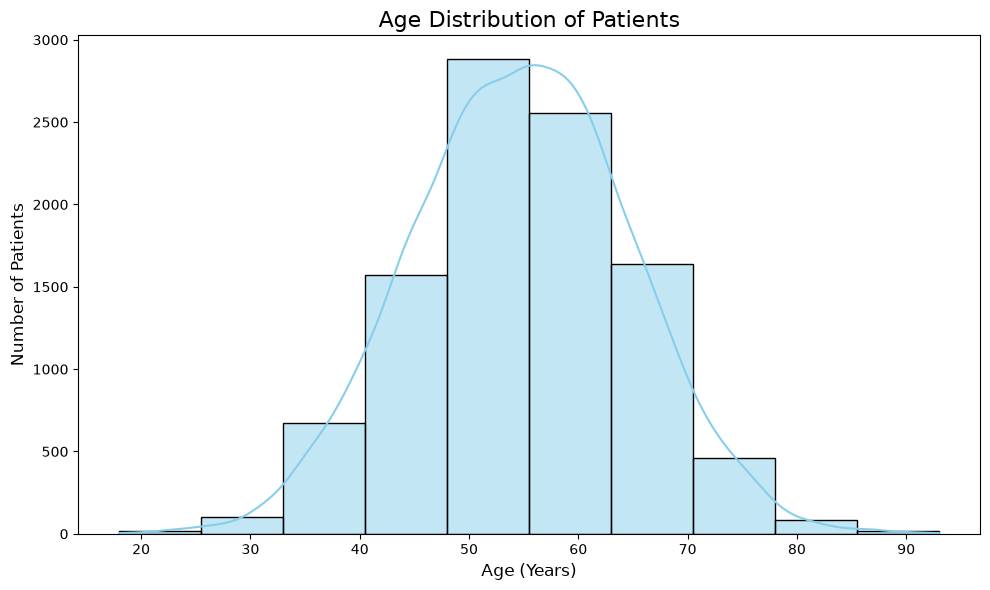

In [4]:
# What is the age distribution of the patients?
# Histogram

print(df['age'].describe())

# Remove missing values from the age column
age = df['age'].dropna()

# Create the histogram
plt.figure(figsize=(10, 6))

sns.histplot(data=age,bins=10,kde=True,color='skyblue',edgecolor='black')

plt.title('Age Distribution of Patients', fontsize=16)
plt.xlabel('Age (Years)', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)

plt.tight_layout()
plt.show()


maximum age range of cancer patients is in between 40 to 70 years.

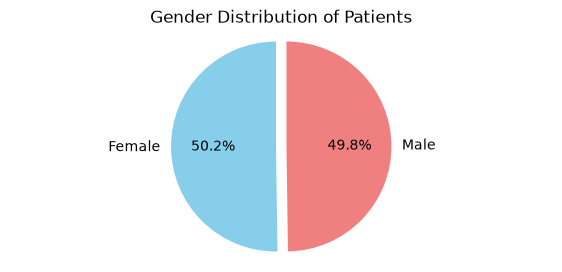

In [5]:
# What is the distribution of patients by gender?
# Pie chart

gender_counts = df['gender'].value_counts()

# Create the pie chart
plt.figure(figsize=(7, 3))

plt.pie(gender_counts,labels=gender_counts.index,autopct='%1.1f%%',startangle=90,colors=['skyblue', 'lightcoral'],
    explode=[0.05] * len(gender_counts)
)

plt.title('Gender Distribution of Patients')
plt.axis('equal')
plt.show()


The ratio of male and female patients are approximately same.

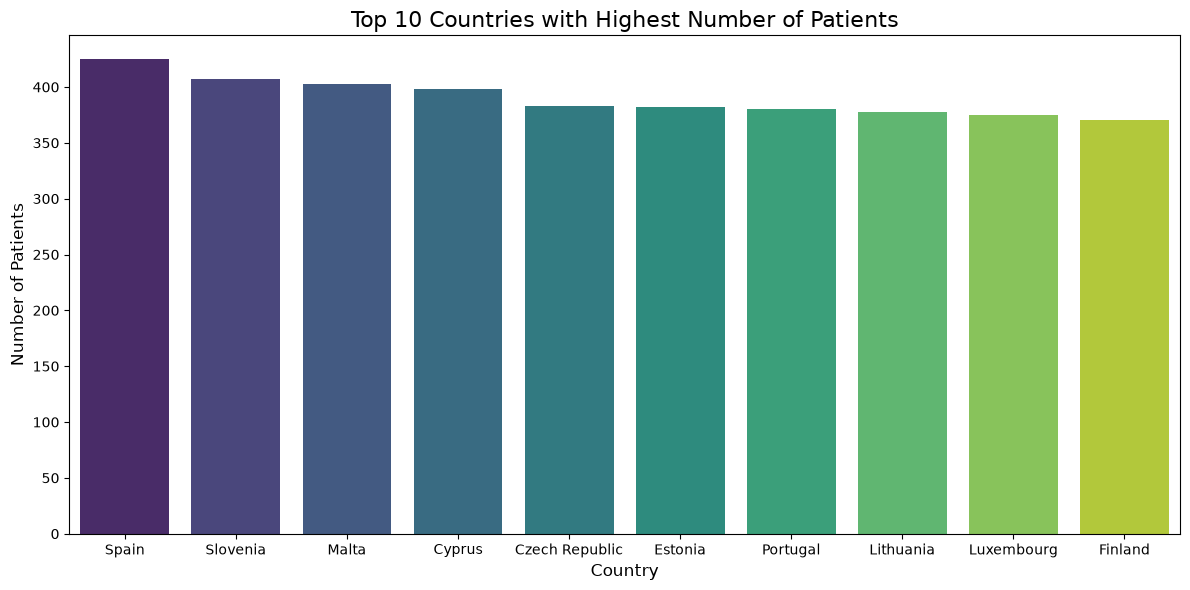

In [6]:
# Which countries have the highest number of patients?
# Bar chart

country_counts = df['country'].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=country_counts.index, y=country_counts.values, hue=country_counts.index, palette='viridis')

plt.title('Top 10 Countries with Highest Number of Patients', fontsize=16)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)
plt.tight_layout()
plt.show()

The maximum number of cancer patients registered are from Spain.

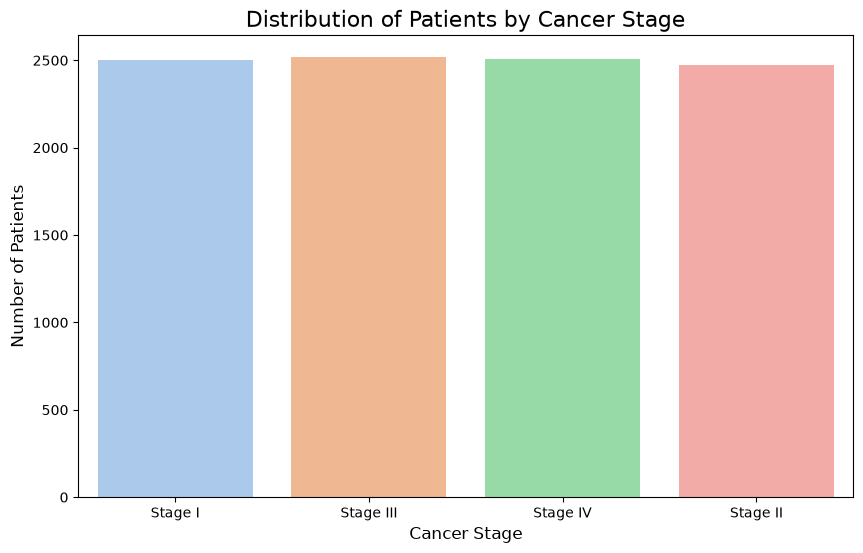

In [7]:
# How are patients distributed across cancer stages (Stage I–IV)?
# Countplot 
plt.figure(figsize=(10, 6))

sns.countplot(x='cancer_stage', data=df, hue='cancer_stage', palette='pastel')

plt.title('Distribution of Patients by Cancer Stage', fontsize=16)
plt.xlabel('Cancer Stage', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)
plt.show()

cancer_stage    Stage I  Stage II  Stage III  Stage IV
smoking_status                                        
Current Smoker      636       616        675       605
Former Smoker       630       642        651       568
Never Smoked        626       616        608       663
Passive Smoker      611       598        584       671


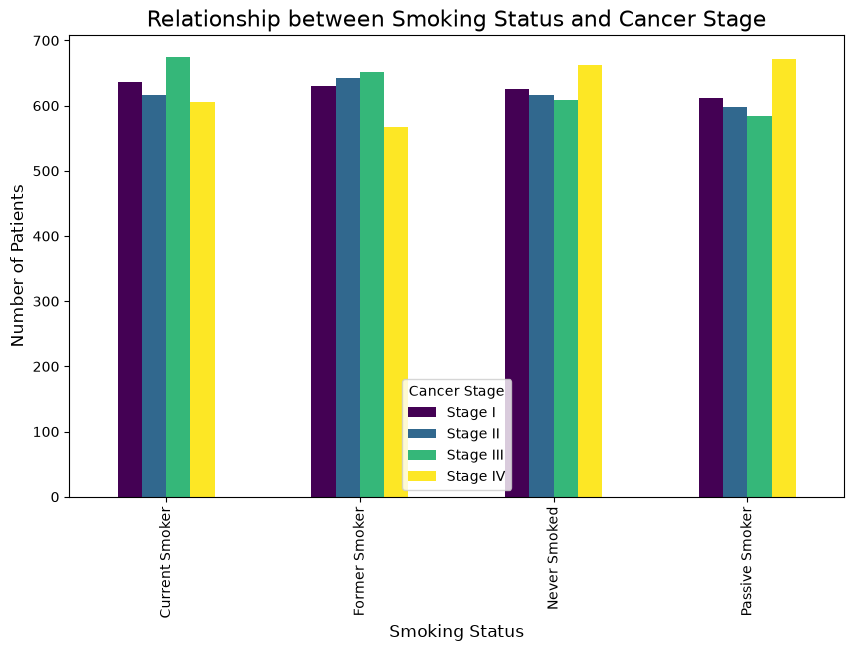

In [8]:
# What is the relationship between smoking status and cancer stage?
# Crosstab + bar chart

crosstab = pd.crosstab(df['smoking_status'], df['cancer_stage'])
print(crosstab)

crosstab.plot(kind='bar',figsize=(10, 6), colormap='viridis')

plt.title('Relationship between Smoking Status and Cancer Stage', fontsize=16)
plt.xlabel('Smoking Status', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)
plt.legend(title='Cancer Stage')

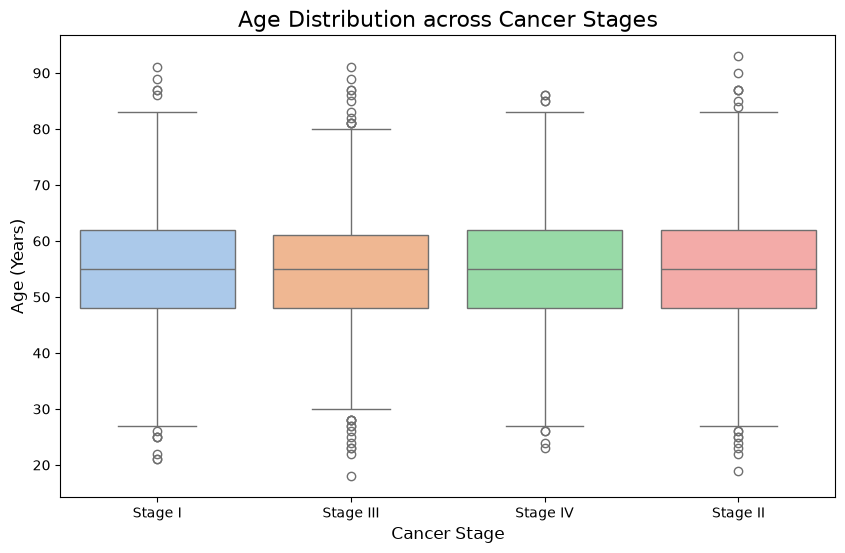

In [9]:
# Does age differ significantly across cancer stages?
# Boxplot
plt.figure(figsize=(10, 6))

sns.boxplot(x='cancer_stage', y='age', data=df,hue='cancer_stage', palette='pastel')

plt.title('Age Distribution across Cancer Stages', fontsize=16)
plt.xlabel('Cancer Stage', fontsize=12)
plt.ylabel('Age (Years)', fontsize=12)
plt.show()

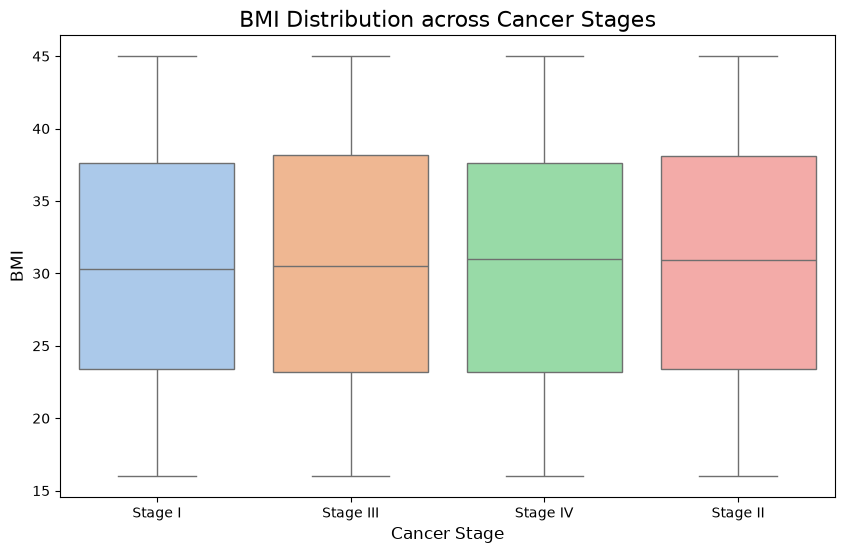

In [10]:
# How does BMI vary across different cancer stages?
# Boxplot

plt.figure(figsize=(10, 6))

sns.boxplot(x='cancer_stage', y='bmi', data=df,hue='cancer_stage', palette='pastel')
plt.title('BMI Distribution across Cancer Stages', fontsize=16)
plt.xlabel('Cancer Stage', fontsize=12)
plt.ylabel('BMI', fontsize=12)
plt.show()

treatment_type  Chemotherapy  Combined  Radiation  Surgery
smoking_status                                            
Current Smoker           634       619        639      640
Former Smoker            616       633        641      601
Never Smoked             608       604        643      658
Passive Smoker           638       602        603      621


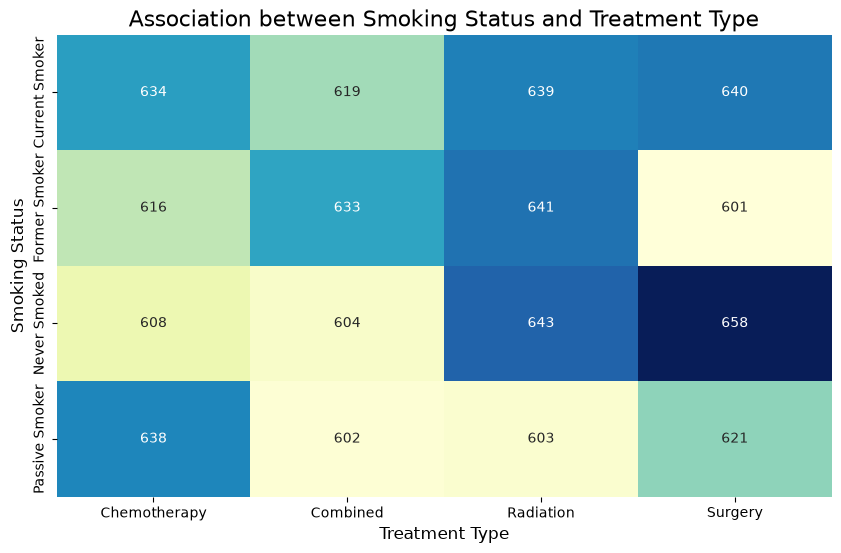

In [11]:
# Is smoking status associated with the treatment received?
# Crosstab + heatmap

crosstab = pd.crosstab(df['smoking_status'], df['treatment_type'])
print(crosstab)

plt.figure(figsize=(10, 6))

sns.heatmap(crosstab, annot=True, fmt='d', cmap='YlGnBu', cbar=False)

plt.title('Association between Smoking Status and Treatment Type', fontsize=16)
plt.xlabel('Treatment Type', fontsize=12)
plt.ylabel('Smoking Status', fontsize=12)
plt.show()

treatment_type  Chemotherapy  Combined  Radiation  Surgery
cancer_stage                                              
Stage I                  611       641        637      614
Stage II                 619       608        613      632
Stage III                632       579        656      651
Stage IV                 634       630        620      623


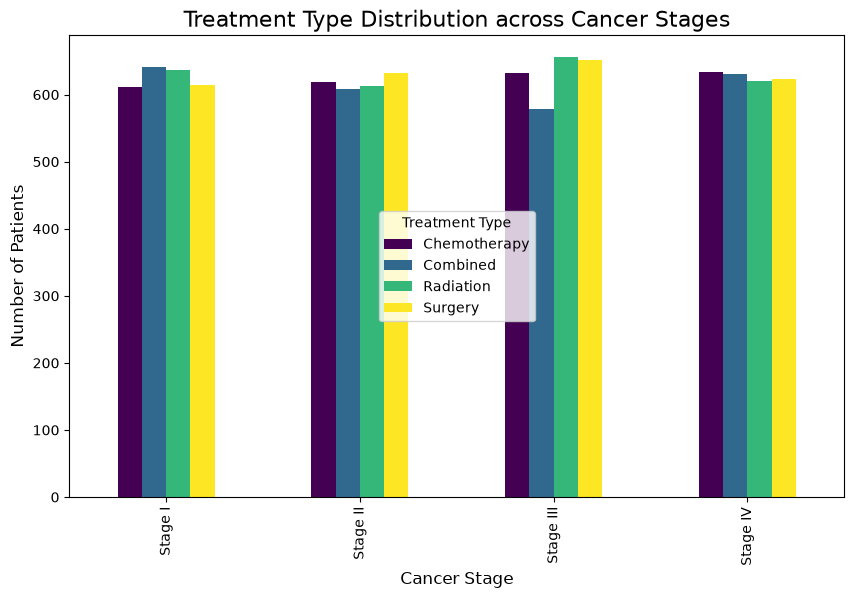

In [12]:
# Which treatment type is most frequently used for each cancer stage?
# bar chart

crosstab = pd.crosstab(df['cancer_stage'], df['treatment_type'])
print(crosstab)

crosstab.plot(kind='bar',figsize=(10, 6), colormap='viridis')

plt.title('Treatment Type Distribution across Cancer Stages', fontsize=16)
plt.xlabel('Cancer Stage', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)
plt.legend(title='Treatment Type',loc='center')
plt.show()

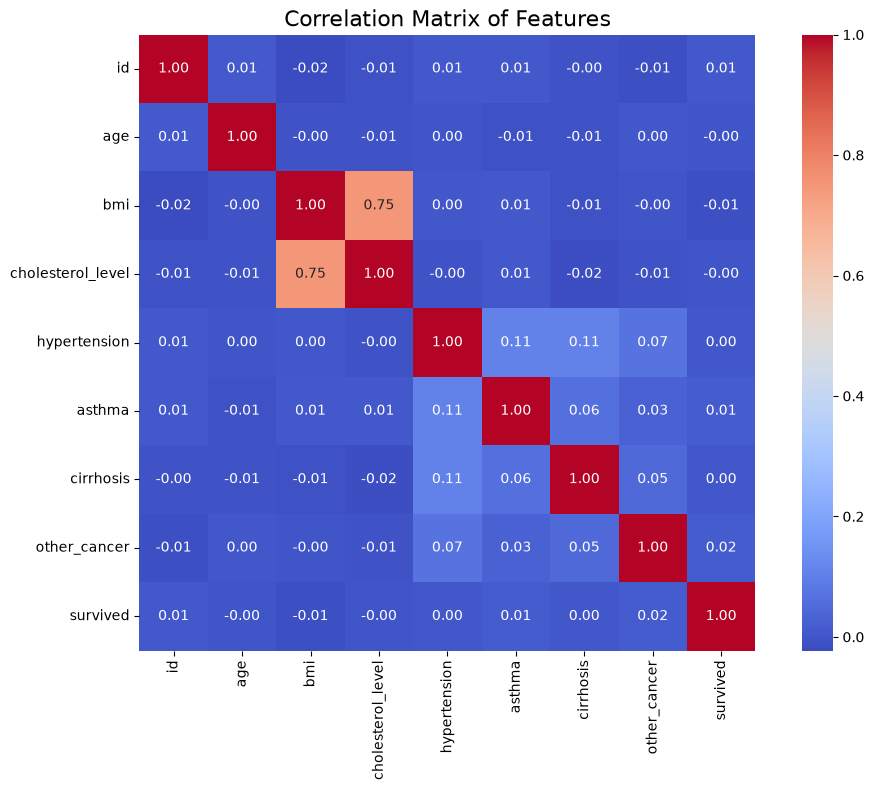

In [13]:
# What factors are associated with the binary outcome in the dataset?
# Correlation matrix

plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include="number")

corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)

plt.title('Correlation Matrix of Features', fontsize=16)
plt.show()

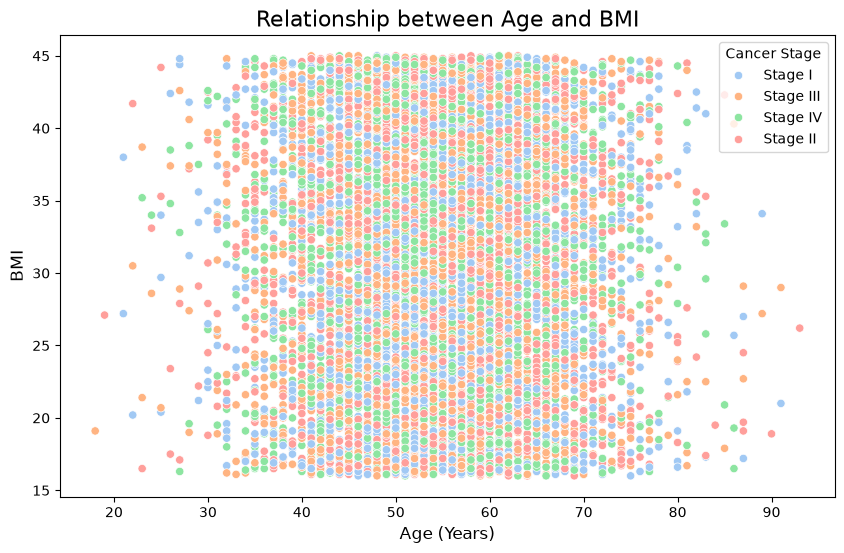

In [14]:
# Is there a relationship between age and BMI?
# Scatter plot

plt.figure(figsize=(10, 6))

sns.scatterplot(x='age', y='bmi', data=df, hue='cancer_stage', palette='pastel')

plt.title('Relationship between Age and BMI', fontsize=16)
plt.xlabel('Age (Years)', fontsize=12)
plt.ylabel('BMI', fontsize=12)
plt.legend(title='Cancer Stage')
plt.show()

In [19]:
df

,id,age,gender,country,diagnosis_date,cancer_stage,family_history,smoking_status,bmi,cholesterol_level,hypertension,asthma,cirrhosis,other_cancer,treatment_type,end_treatment_date,survived
0,1,64,Male,Sweden,2016-04-05,Stage I,Yes,Passive Smoker,29.4,199,0,0,1,0,Chemotherapy,end_treatment_date,0
1,2,50,Female,Netherlands,2023-04-20,Stage III,Yes,Passive Smoker,41.2,280,1,1,0,0,Surgery,end_treatment_date,1
2,3,65,Female,Hungary,2023-04-05,Stage III,Yes,Former Smoker,44.0,268,1,1,0,0,Combined,end_treatment_date,0
3,4,51,Female,Belgium,2016-02-05,Stage I,No,Passive Smoker,43.0,241,1,1,0,0,Chemotherapy,end_treatment_date,0
4,5,37,Male,Luxembourg,2023-11-29,Stage I,No,Passive Smoker,19.7,178,0,0,0,0,Combined,end_treatment_date,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,65,Male,Cyprus,2024-05-10,Stage I,Yes,Passive Smoker,33.9,277,1,1,0,0,Combined,end_treatment_date,1
9996,9997,61,Female,Malta,2015-09-30,Stage I,No,Current Smoker,33.2,282,1,0,0,0,Surgery,end_treatment_date,0
9997,9998,52,Male,Sweden,2022-11-10,Stage I,No,Passive Smoker,27.0,156,1,0,0,0,Radiation,end_treatment_date,1
9998,9999,69,Male,Netherlands,2021-03-23,Stage IV,No,Former Smoker,42.6,261,1,1,1,0,Surgery,end_treatment_date,0
